# Attacking AES Without A Trigger

**This tutorial can only be completed using the [CW1200 ChipWhisperer Pro](https://wiki.newae.com/CW1200_ChipWhisperer-Pro)**

Throughout all of our tutorials, we've been relying on our target to provide a nice rising edge trigger for us to start our ADC capture on. As you might expect, this isn't something we can rely on in a real attack. This tutorial will focus on using two of the ChipWhisperer Pro's exclusive features, stream mode and the Sum of Absolute Difference (SAD) module, to break a more realistic target.

As usual, we'll start by setting up the firmware for the target.

If you want to *totally* remove the trigger, navigate to `../../firmware/mcu/simpleserial-aes` and open `simpleserial-aes.c` in your favourite text editor. Find the following code and comment out `trigger_high();` and `trigger_low();`:

```C
uint8_t get_pt(uint8_t* pt)
{
	trigger_high();
	aes_indep_enc(pt); /* encrypting the data block */
	trigger_low();
	simpleserial_put('r', 16, pt);
	return 0x00;
}
```

Then build the firmware:

In [1]:
SCOPETYPE = 'OPENADC'
PLATFORM = 'CWHUSKY'
# do not work for SAM4S  CRYPTO_TARGET = 'AVRCRYPTOLIB'
CRYPTO_TARGET='TINYAES128C' 

In [2]:
%%bash -s "$PLATFORM" "$CRYPTO_TARGET"
cd ../../firmware/mcu/simpleserial-aes
make PLATFORM=$1 CRYPTO_TARGET=$2

Building for platform CWHUSKY with CRYPTO_TARGET=TINYAES128C
SS_VER set to SS_VER_1_1
SS_VER set to SS_VER_1_1
Blank crypto options, building for AES128
.
Welcome to another exciting ChipWhisperer target build!!
arm-none-eabi-gcc (15:14.2.rel1-1) 14.2.1 20241119
Copyright (C) 2024 Free Software Foundation, Inc.
This is free software; see the source for copying conditions.  There is NO
warranty; not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.

mkdir -p objdir-CWHUSKY 
.
Compiling:
-en     simpleserial-aes.c ...
-e Done!
.
Compiling:
-en     .././simpleserial/simpleserial.c ...
-e Done!
.
Compiling:
-en     .././hal/hal.c ...
-e Done!
.
Compiling:
-en     .././hal//sam4s/startup_sam4s.c ...
-e Done!
.
Compiling:
-en     .././hal//sam4s/sam4s_hal.c ...
-e Done!
.
Compiling:
-en     .././hal//sam4s/uart.c ...
-e Done!
.
Compiling:
-en     .././hal//sam4s/pio.c ...
-e Done!
.
Compiling:
-en     .././hal//sam4s/system_sam4s.c ...
-e Done!
.
Compiling:
-en     .././hal//sam4

## The plan

With your experience with the ChipWhisperer and power analysis attacks up to this point, you might expect that without those `trigger_high();` and `trigger_low();` calls, attacking this target will be extremely difficult. In reality, with the ChipWhisperer Pro, we can boil this down into a simple two step plan:

1. Use the Pro's stream mode feature to record a power wave that will encompass a long peroid of the target's operation (say a tenth of a second)
1. Find where AES is happening and use it as a reference for the SAD module. This module allows the ChipWhisperer to trigger based on a 128 sample long unique portion of a power wave and will replace the rising edge trigger we had in earlier tutorials.

More details about what stream mode and SAD do and their limitations will be explained as we go through the tutorial. With that said, let's get to work on implementing this plan!

## Setup and Stream Mode

To start, we'll setup the scope as usual:

In [3]:
%run "../Setup_Scripts/Setup_Generic.ipynb"

INFO: Found ChipWhisperer😍
scope.gain.gain                          changed from 0                         to 22                       
scope.gain.db                            changed from 15.0                      to 25.091743119266056       
scope.adc.samples                        changed from 346246                    to 5000                     
scope.clock.clkgen_freq                  changed from 0                         to 7363636.363636363        
scope.clock.adc_freq                     changed from 0                         to 29454545.454545453       
scope.clock.adc_rate                     changed from 0.0                       to 29454545.454545453       
scope.io.tio1                            changed from serial_tx                 to serial_rx                
scope.io.tio2                            changed from serial_rx                 to serial_tx                
scope.io.hs2                             changed from None                      to clkgen            

And program the device:

In [4]:
fw_path = '../../firmware/mcu/simpleserial-aes/simpleserial-aes-{}.hex'.format(PLATFORM)
cw.program_target(scope, prog, fw_path)

Next, let's get into what stream mode is. Essentially, stream mode allows the ChipWhisperer software to continuously read power measurements back from the scope enabling extremely long captures. In theory, there's no limit to how long these captures can be, but keep in mind very long wave (in the millions of samples) can easily outstrip your computer's memory. Even if you can store the wave itself, doing anything else with the wave may cause memory errors.

Stream mode does have one major limit though: sample rate. With stream mode enabled, the Pro can only record traces at a sample rate of less than 10MHz. Our typical 4\*7.37MHz ADC clock easily outpaces that, so we'll need to change our clocksource to be 7.37MHz instead:

In [23]:
print(scope.clock.clkgen_src)
print(scope.trigger.triggers)
print(scope.clock.adc_mul)

system
tio4
4


In [24]:
#scope.clock.adc_src = "clkgen_x1"
scope.clock.clkgen_src = "system"
scope.clock.adc_mul = 1

Stream mode itself is pretty easy to enable:

In [6]:
scope.adc.stream_mode = True

We'll need to set our regular trigger to be `"low"` so that the scope will immediately trigger and start capturing after being armed:

In [7]:
scope.adc.basic_mode = "low"

We can now set the number of samples to capture to be much higher. Let's set it to 1M traces, just to be safe:

In [25]:
scope.adc.samples=1000000

That's it! We can now capture a very long trace (give this one a second to complete):

In [26]:
ktp = cw.ktp.Basic()
key, text = ktp.next()
ret = cw.capture_trace(scope, target, text, key)

And then plot it. We'll need to do some preprocessing on the trace using `datashade()`, since trying to plot the trace normally will take far too long:

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
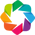

:DynamicMap   []
   :RGB   [x,y]   (R,G,B,A)

In [27]:
import holoviews as hv
from holoviews.operation import decimate
from holoviews.operation.datashader import datashade
hv.extension('bokeh')
datashade(hv.Curve(ret.trace)).opts(width=900, height=600)

You should see something like this:
    
![Stream mode 1](https://wiki.newae.com/images/8/89/Stream_mode_1.png)

That distinctive part near the beginning is where everything is happening. Within that, we can see three separate sections:

1. The target receiving the plaintext
1. AES
1. The target sending the ciphertext back to us

Zoom into the middle section:

![Stream mode 2](https://wiki.newae.com/images/9/96/Stream_mode_2.png)

Then further into the beginning of AES:

![Stream mode 3](https://wiki.newae.com/images/6/64/Stream_mode_3.png)

And find a fairly unique area. You actually don't want to select the transition between receiving the plaintext and `get_pt()` here since that serial data is actually fairly noisy. You also don't want to select after where AES has started (hint: it may be good to refer back to PA_CPA_1 for what the start of AES looks like). Instead look for something like this:

![Stream mode 4](https://wiki.newae.com/images/9/91/Stream_mode_4.png)

Which looks like this zoomed in:

![Stream mode 5](https://wiki.newae.com/images/a/aa/Stream_mode_5.png)

Looking at our data from PA_CPA_1, we can see we're actually around the beginning of AES:

![Stream mode 6](https://wiki.newae.com/images/d/dd/Stream_mode_7.png)

Let's select a good starting point for our reference. Keep in mind that our reference will only be 128 samples long. In our case, we selected `1.444E5` as a reference. Don't worry too much about getting a perfect spot, you'll have a few oppotunities to check your reference and make sure it works fine. We'll also need to turn stream mode off.

In [28]:
#point = int(1.444E5)
point = int(90000)
scope.adc.stream_mode = False

Now that we have a reference area, we're ready to start using the SAD module and finish the attack!

## The SAD Module

As mentioned earlier, the SAD module will allow us to trigger based on the trace reference we just selected. The way it does this is also fairly simple: as trace data comes in it's compared to the reference using the SAD equation. If this comparison falls below a threshold, the trigger event occurs and we'll start capturing our wave. The SAD equation is as follows:

$$S A D = \sum _ { i = 1 } ^ { 128 } \left| x _ { A D C , i } - x _ { p a t t e r n , i } \right|$$

which, as you can see, is just the sum of the absolute value of the difference between each point and the reference (a.k.a. the Sum of Absolute Difference). Basically, when the difference between the current trace data and the reference falls below a certain level, the SAD module knows it has reached the right spot.

Now that you know how it works, let's setup the SAD module. We'll start by setting our reference:

In [29]:
scope.SAD.reference = ret.trace[point:point+128]

Let's see what it looks like:

In [30]:
hv.Curve(scope.SAD.reference).opts(width=900, height=600)

:Curve   [x]   (y)

That should hopefully look fairly close to the area you selected. Next we'll set a threshold. You may have to experiment a bit with this value. If your trigger keeps timing out, try increasing the threshold. If it's selecting the wrong point or you're getting a lot of jitter, try lowering it. Otherwise, you may need to select a different reference trace. 5000 is typically a good starting point:

In [32]:
scope.SAD.threshold = 50

Next, we'll start the SAD module:

In [34]:
# not for husky scope.SAD.start()

And change our trigger module to be SAD. SAD outputs a rising edge trigger internally, so we'll need to change that as well:

In [35]:
scope.trigger.module = "SAD"
scope.adc.basic_mode = "rising_edge"

We'll only need to capture 5000 samples at most to break AES here:

In [36]:
scope.adc.samples=5000

Let's print our scope and see what our settings look like:

In [37]:
print(scope)

cwhuskyplus Device
sn             = 50203220573555303130353137323034
fpga_buildtime = 9/25/2026, 15:32
fw_version = 
    major = 1
    minor = 2
    debug = 0
gain = 
    mode = high
    gain = 22
    db   = 25.091743119266056
adc = 
    state                    = False
    basic_mode               = rising_edge
    timeout                  = 2
    offset                   = 0
    presamples               = 0
    samples                  = 5000
    decimate                 = 1
    trig_count               = 1991267354
    stream_mode              = False
    test_mode                = False
    bits_per_sample          = 12
    segments                 = 1
    segment_cycles           = 0
    segment_cycle_counter_en = False
    clip_errors_disabled     = False
    lo_gain_errors_disabled  = False
    errors                   = segmenting error, 
clock = 
    clkgen_src             = system
    clkgen_freq            = 7363636.363636363
    adc_mul                = 1
    adc_freq      

Before we get into the actual attack, let's also capture a few test traces and plot them. Make sure you let this loop go to completion, even if it's timing out; interrupting the capture can sometimes put the ChipWhisperer into an oddly configured state, requiring a power cycle (this is rare, but seems more common with SAD trigger).

In [39]:
from tqdm import tnrange
project = cw.Project("projects/Tutorial_B5", overwrite = True)
for i in tnrange(3, desc='Capturing traces'):
    key, text = ktp.next()  # manual creation of a key, text pair can be substituted here
    trace = cw.capture_trace(scope, target, text, key)
    if trace is None:
        continue
    project.traces.append(trace)

/tmp/ipykernel_21143/4270020308.py:3: TqdmDeprecationWarning: Please use `tqdm.notebook.trange` instead of `tqdm.tnrange`
  for i in tnrange(3, desc='Capturing traces'):


Capturing traces:   0%|          | 0/3 [00:00<?, ?it/s]

(ChipWhisperer Scope WARNING|File _OpenADCInterface.py:797) Timeout in OpenADC capture(), no trigger seen! Trigger forced, data is invalid. Status: 13
(ChipWhisperer Scope WARNING|File _OpenADCInterface.py:797) Timeout in OpenADC capture(), no trigger seen! Trigger forced, data is invalid. Status: 12
(ChipWhisperer Scope WARNING|File __init__.py:390) Timeout happened during capture
(ChipWhisperer Scope WARNING|File _OpenADCInterface.py:797) Timeout in OpenADC capture(), no trigger seen! Trigger forced, data is invalid. Status: 13
(ChipWhisperer Scope WARNING|File _OpenADCInterface.py:797) Timeout in OpenADC capture(), no trigger seen! Trigger forced, data is invalid. Status: 12
(ChipWhisperer Scope WARNING|File __init__.py:390) Timeout happened during capture
(ChipWhisperer Scope WARNING|File _OpenADCInterface.py:797) Timeout in OpenADC capture(), no trigger seen! Trigger forced, data is invalid. Status: 13
(ChipWhisperer Scope WARNING|File _OpenADCInterface.py:797) Timeout in OpenADC 

If you got traces from that plot them. If not, go back and adjust your reference/threshold.

In [ ]:
hv.Curve(project.trace[0]).opts(width=900, height=600) * hv.Curve(project.trace[1]).opts(width=900, height=600) * hv.Curve(project.trace[2]).opts(width=900, height=600)

These hopefully look good. Next, let's run our attack:

In [ ]:
from tqdm import tnrange
project = cw.Project()
for i in tnrange(100, desc='Capturing traces'):
    key, text = ktp.next()  # manual creation of a key, text pair can be substituted here
    trace = cw.capture_trace(scope, target, text, key)
    if trace is None:
        continue
    project.append(trace)
project.save("projects/Tutorial_B5", overwrite = True)

## Analysis

Analysis is super simple here: it's just a standard CPA attack at this point.

In [ ]:
import chipwhisperer.analyzer as cwa
leak_model = cwa.leakage_models.sbox_output
attack = cwa.CPA(project, leak_model, 16)

In [ ]:
results = attack.run(100, cwa.get_jupyter_cb())

And the result is:

In [ ]:
print(results)

Comparing to the correct key, you should find that you've successully conducted the attack:

In [ ]:
print(results.key_guess(), "\n", list(project.keys[0]))

## Conclusion

In this tutorial we have learned to use two of the CW1200_ChipWhisperer-Pro's exclusive features stream mode and SAD Trigger. The stream feature allows us the continually stream and manually send plain text to the target to observe the encryption process. Then 128 sample points that make up a unique feature of the encryption process where chosen to activate the trigger during trace capture. These two features together can be used to break the AES encryption of a device without any help from the target. 

## Tests

In [ ]:
assert results.key_guess() == list(project.keys[0]), "Failed to break key!\nGot: {}\nExp: {}".format(results.key_guess(), list(project.keys[0]))